# LSTM for fraud detection (IEEE-CIS)

**Abdullah Balilah** · Deep Learning project, *Fraud Detection in FinTech*

**Idea.** A normal model looks at each payment alone. An LSTM can also look at the **earlier payments of the same
client**, in time order. Here we test whether that history helps.

**Setup (same as the team plan).**
- Data: the team's file `ieee_sorted_split.parquet` (590,540 payments, sorted by time, split 70 / 15 / 15).
- Columns: column set A from the reference paper (Table 2): 390 columns.
- Preprocessing fitted on the training part only: median fill, standardise, categories learned from training (unseen = "unknown").
- Loss: weighted binary cross-entropy, fraud weight √(N0/N1). Optimizer: Adam.
- Model selection: best validation ROC-AUC, patience 10, up to 80 epochs. The test set is scored once at the end.
- Seeds 42, 1 and 2.

Runtime: Colab, T4 GPU. Data and results are kept in Google Drive (`MyDrive/fraud_detection_project`).

In [14]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

QUICK = False   # True = 2 epochs and 1 seed, only to test that the notebook runs

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "none")

GPU: Tesla T4


## 1. Load the data

In [15]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/fraud_detection_project")
OUT = PROJECT / "results" / "lstm"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROJECT / "data" / "ieee_sorted_split.parquet")
print(df.shape)
df.groupby("split", sort=False).agg(payments=("isFraud", "size"), fraud_rate=("isFraud", "mean")).round(4)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(590540, 435)


,payments,fraud_rate
split,,
train,413378,0.0352
val,88581,0.0343
test,88581,0.0348


## 2. Column set A and preprocessing

Column set A = `TransactionAmt`, `card1`–`card6`, `addr1`–`addr2`, `P_emaildomain`, `R_emaildomain`, `DeviceType`,
`DeviceInfo`, `id_01`–`id_38`, `V1`–`V339`. Text columns get a small embedding; numbers are median-filled and
standardised. All statistics come from the training payments only.

In [16]:
SET_A = (["TransactionAmt"] + [f"card{i}" for i in range(1, 7)] + ["addr1", "addr2", "P_emaildomain", "R_emaildomain",
         "DeviceType", "DeviceInfo"] + [f"id_{i:02d}" for i in range(1, 39)] + [f"V{i}" for i in range(1, 340)])
assert len(SET_A) == 390

is_train = (df["split"] == "train").to_numpy()
cat_cols = [c for c in SET_A if df[c].dtype == object]
num_cols = [c for c in SET_A if c not in cat_cols]
print(len(num_cols), "number columns,", len(cat_cols), "text columns")

# numbers: fill with the training median, standardise with the training mean and std
X_num = df[num_cols].to_numpy(np.float32)
median = np.nan_to_num(np.nanmedian(X_num[is_train], axis=0))
X_num = np.where(np.isnan(X_num), median, X_num)
mean, std = X_num[is_train].mean(0), X_num[is_train].std(0) + 1e-6
X_num = np.clip((X_num - mean) / std, -10, 10).astype(np.float32)

# text columns: 0 = missing, 1 = not seen in training, 2.. = values seen in training
X_cat = np.zeros((len(df), len(cat_cols)), np.int64)
cat_sizes = []
for j, c in enumerate(cat_cols):
    values = df.loc[is_train, c].dropna().unique()
    code = df[c].map({v: i + 2 for i, v in enumerate(values)})
    X_cat[:, j] = np.where(df[c].isna(), 0, code.fillna(1)).astype(np.int64)
    cat_sizes.append(len(values) + 2)

369 number columns, 21 text columns


## 3. Payment history of each client

The data has no client id, so a client is approximated by **card1 + addr1** (card number field + billing address).
The file is sorted by time, so for every payment we can look up the previous payments of the same client.
Only earlier payments are used, never later ones.

In [17]:
client = pd.factorize(df["card1"].astype(str) + "_" + df["addr1"].astype(str))[0]
order = np.argsort(client, kind="stable")          # grouped by client, time order kept inside each client
prev = np.full(len(df), -1)
same = client[order][1:] == client[order][:-1]
prev[order[1:][same]] = order[:-1][same]           # index of the client's previous payment (-1 = none)

def make_windows(W):
    # row i -> indices of the client's last W payments, oldest first, ending with payment i
    idx = np.empty((len(df), W), np.int64)
    idx[:, -1] = np.arange(len(df))
    for k in range(W - 2, -1, -1):
        p = idx[:, k + 1]
        idx[:, k] = np.where(p >= 0, prev[np.maximum(p, 0)], -1)
    idx[idx < 0] = len(df)                          # padding row (all zeros)
    return idx

In [18]:
# number of earlier payments of the same client, and the fraud rate for each group
rank = pd.Series(client).groupby(client).cumcount().to_numpy()
groups = pd.cut(rank, [-1, 0, 4, 19, 10**9], labels=["first payment", "1-4 earlier", "5-19 earlier", "20+ earlier"])
history = pd.DataFrame({"group": groups, "split": df["split"], "fraud": df["isFraud"]})
table = history.groupby(["group", "split"], observed=True)["fraud"].agg(["size", "mean"]).unstack("split")
table.columns = [f"{a}_{b}" for a, b in table.columns]
print("clients:", client.max() + 1)
table[["size_train", "size_test", "mean_train", "mean_test"]].rename(columns={"mean_train": "fraud_rate_train", "mean_test": "fraud_rate_test"}).round(4)

clients: 39974


,size_train,size_test,fraud_rate_train,fraud_rate_test
group,,,,
first payment,34755,2494,0.0257,0.0385
1-4 earlier,59044,5635,0.0267,0.0293
5-19 earlier,80633,11298,0.0279,0.0285
20+ earlier,238946,69154,0.0411,0.0362


## 4. Model

Each payment in the window → embeddings of its text columns + its numbers → `Linear` (64) → **LSTM** (64) → the
output after the last (current) payment → `Linear` → fraud score. `W = 8` means the model sees the current payment
and up to 7 earlier ones. `W = 1` is the same network without history, used as the comparison.

In [19]:
class FraudLSTM(nn.Module):
    def __init__(self, n_num, cat_sizes, emb_dim=4, hidden=64):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, emb_dim) for n in cat_sizes])
        self.inp = nn.Linear(n_num + emb_dim * len(cat_sizes), hidden)
        self.lstm = nn.LSTM(hidden, hidden, batch_first=True)
        self.drop = nn.Dropout(0.2)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x_num, x_cat):
        e = [emb(x_cat[..., j]) for j, emb in enumerate(self.embs)]
        h = torch.relu(self.inp(torch.cat([x_num] + e, dim=-1)))
        h, _ = self.lstm(h)
        return self.out(self.drop(h[:, -1])).squeeze(-1)

# all features on the GPU, plus one zero row for padding
Xn = torch.tensor(np.vstack([X_num, np.zeros((1, X_num.shape[1]), np.float32)]), device=DEVICE)
Xc = torch.tensor(np.vstack([X_cat, np.zeros((1, X_cat.shape[1]), np.int64)]), device=DEVICE)
y = df["isFraud"].to_numpy(np.float32)
rows = {s: np.flatnonzero(df["split"].to_numpy() == s) for s in ("train", "val", "test")}
n1, n0 = y[rows["train"]].sum(), (1 - y[rows["train"]]).sum()
POS_WEIGHT = float(np.sqrt(n0 / n1))
print(f"fraud weight sqrt(N0/N1) = {POS_WEIGHT:.2f}")

fraud weight sqrt(N0/N1) = 5.24


## 5. Training

In [20]:
@torch.no_grad()
def predict(model, win, idx, batch=8192):
    model.eval()
    out = []
    for i in range(0, len(idx), batch):
        w = win[torch.as_tensor(idx[i:i + batch], device=DEVICE)]
        out.append(model(Xn[w], Xc[w]).float().cpu())
    return torch.cat(out).numpy()


def train_run(name, W, seed, max_epochs=80, patience=10, batch=1024, lr=1e-3):
    torch.manual_seed(seed)
    np.random.seed(seed)
    start = time.time()
    win = torch.as_tensor(make_windows(W), device=DEVICE)
    model = FraudLSTM(Xn.shape[1], cat_sizes).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))
    y_gpu = torch.as_tensor(y, device=DEVICE)
    train_idx = torch.as_tensor(rows["train"], device=DEVICE)

    history, best_roc, best_epoch, best_state = [], -1, 0, None
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = train_idx[torch.randperm(len(train_idx), device=DEVICE)]
        total = 0.0
        for i in range(0, len(perm), batch):
            r = perm[i:i + batch]
            w = win[r]
            loss = loss_fn(model(Xn[w], Xc[w]), y_gpu[r])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(r)
        val_score = predict(model, win, rows["val"])
        val_roc = roc_auc_score(y[rows["val"]], val_score)
        val_pr = average_precision_score(y[rows["val"]], val_score)
        history.append({"epoch": epoch, "loss": total / len(perm), "val_roc_auc": val_roc, "val_pr_auc": val_pr})
        if val_roc > best_roc:
            best_roc, best_epoch = val_roc, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= patience:
            break

    model.load_state_dict(best_state)
    scores = {s: predict(model, win, rows[s]) for s in ("val", "test")}   # test is scored only here
    for s, score in scores.items():
        pd.DataFrame({"TransactionID": df["TransactionID"].to_numpy()[rows[s]], "isFraud": y[rows[s]],
                      "score": score}).to_parquet(OUT / f"{name}_{s}.parquet", index=False)
    minutes = (time.time() - start) / 60
    info = {"model": "LSTM", "column_set": "A", "window": W, "seed": seed, "chosen_epoch": best_epoch,
            "settings": {"lr": lr, "batch": batch, "hidden": 64, "emb_dim": 4, "dropout": 0.2,
                         "max_epochs": max_epochs, "patience": patience, "fraud_weight": POS_WEIGHT},
            "epochs": history}
    (OUT / f"{name}_history.json").write_text(json.dumps(info, indent=1))
    result = {"run": name, "W": W, "seed": seed,
              "test_roc_auc": roc_auc_score(y[rows["test"]], scores["test"]),
              "test_pr_auc": average_precision_score(y[rows["test"]], scores["test"]),
              "best_epoch": best_epoch, "minutes": round(minutes, 1)}
    print(f"{name:24s} best epoch {best_epoch:2d} | test ROC-AUC {result['test_roc_auc']:.4f} "
          f"PR-AUC {result['test_pr_auc']:.4f} | {minutes:.1f} min")
    return result, history, scores["test"]

In [21]:
SEEDS = [42] if QUICK else [42, 1, 2]
EPOCHS = 2 if QUICK else 80

results, histories, test_scores = [], {}, {}
for W, label in [(8, "lstm_A"), (1, "lstm_nohistory_A")]:
    for seed in SEEDS:
        name = f"{label}_seed{seed}"
        r, h, s = train_run(name, W, seed, max_epochs=EPOCHS)
        results.append(r)
        histories[name], test_scores[name] = h, s

results = pd.DataFrame(results)
results.to_csv(OUT / "results_table.csv", index=False)

lstm_A_seed42            best epoch  2 | test ROC-AUC 0.8642 PR-AUC 0.4189 | 0.8 min
lstm_A_seed1             best epoch  1 | test ROC-AUC 0.8554 PR-AUC 0.4200 | 0.7 min
lstm_A_seed2             best epoch  2 | test ROC-AUC 0.8531 PR-AUC 0.4168 | 0.8 min
lstm_nohistory_A_seed42  best epoch  2 | test ROC-AUC 0.8634 PR-AUC 0.4364 | 0.5 min
lstm_nohistory_A_seed1   best epoch  3 | test ROC-AUC 0.8559 PR-AUC 0.4415 | 0.5 min
lstm_nohistory_A_seed2   best epoch  1 | test ROC-AUC 0.8550 PR-AUC 0.4232 | 0.4 min


## 6. Results (test set)

In [22]:
def mean_range(x):
    return f"{x.mean():.3f} ({x.min():.3f}-{x.max():.3f})"

summary = results.groupby("W").agg(test_roc_auc=("test_roc_auc", mean_range), test_pr_auc=("test_pr_auc", mean_range),
                                   best_epoch=("best_epoch", "mean"), minutes=("minutes", "mean"))
summary.index = ["no history (W=1)" if w == 1 else f"LSTM with history (W={w})" for w in summary.index]
summary

,test_roc_auc,test_pr_auc,best_epoch,minutes
no history (W=1),0.858 (0.855-0.863),0.434 (0.423-0.441),2.000000,0.466667
LSTM with history (W=8),0.858 (0.853-0.864),0.419 (0.417-0.420),1.666667,0.766667


In [23]:
# numbers from the team plan (page 1), same split, for reference
reference = pd.DataFrame([
    ("Plain network, column set A, 3 seeds (team)", 0.841, 0.410),
    ("THGNN, with V, 3 seeds (team)", 0.843, 0.392),
    ("FT-Transformer alone (team)", 0.819, 0.383),
    ("Paper: TabNet-GraphSAGE hybrid", 0.791, 0.206),
    ("Paper: LightGBM", 0.834, 0.394),
], columns=["model", "test ROC-AUC", "test PR-AUC"])
for W, label in [(8, "LSTM with history (W=8), mean of seeds (this notebook)"), (1, "LSTM no history (W=1), mean of seeds (this notebook)")]:
    part = results[results["W"] == W]
    reference.loc[len(reference)] = [label, round(part["test_roc_auc"].mean(), 3), round(part["test_pr_auc"].mean(), 3)]
reference

,model,test ROC-AUC,test PR-AUC
0,"Plain network, column set A, 3 seeds (team)",0.841,0.410
1,"THGNN, with V, 3 seeds (team)",0.843,0.392
2,FT-Transformer alone (team),0.819,0.383
3,Paper: TabNet-GraphSAGE hybrid,0.791,0.206
4,Paper: LightGBM,0.834,0.394
5,"LSTM with history (W=8), mean of seeds (this n...",0.858,0.419
6,"LSTM no history (W=1), mean of seeds (this not...",0.858,0.434


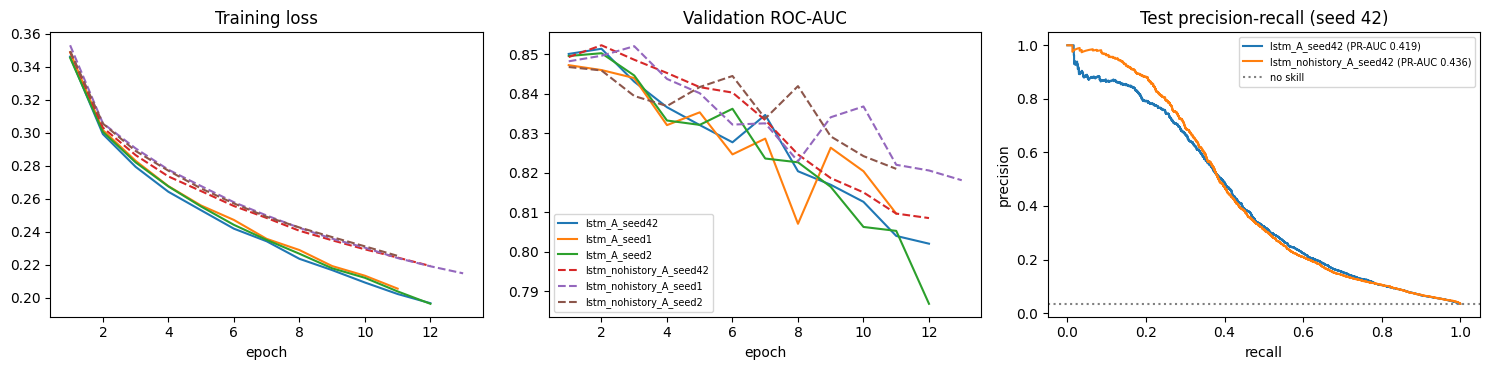

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for name, h in histories.items():
    h = pd.DataFrame(h)
    style = "-" if "nohistory" not in name else "--"
    ax[0].plot(h["epoch"], h["loss"], style, label=name)
    ax[1].plot(h["epoch"], h["val_roc_auc"], style, label=name)
ax[0].set(title="Training loss", xlabel="epoch")
ax[1].set(title="Validation ROC-AUC", xlabel="epoch")
ax[1].legend(fontsize=7)

y_test = y[rows["test"]]
for name in [n for n in test_scores if n.endswith("seed42")]:
    p, r, _ = precision_recall_curve(y_test, test_scores[name])
    ax[2].plot(r, p, label=f"{name} (PR-AUC {average_precision_score(y_test, test_scores[name]):.3f})")
ax[2].axhline(y_test.mean(), color="gray", ls=":", label="no skill")
ax[2].set(title="Test precision-recall (seed 42)", xlabel="recall", ylabel="precision")
ax[2].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "lstm_curves.png", dpi=130)
plt.show()

## 7. Observations

1. **Simple client id.** card1 + addr1 gives 39,974 clients. Most test payments (69,154 of 88,581) belong to a client with 20 or more earlier payments, so this key probably still mixes several people under one "client".
2. **The model learns fast and then overfits.** The best validation epoch was 1 to 3 in every run. After that the training loss keeps going down but the validation ROC-AUC goes down too (see the plot), so early stopping keeps an early epoch.
3. **History did not help.** With the last 8 payments (W = 8): test ROC-AUC 0.858 (0.853-0.864), PR-AUC 0.419 (0.417-0.420). Without history (W = 1): ROC-AUC 0.858 (0.855-0.863), PR-AUC 0.434 (0.423-0.441). For every seed the no-history model had the higher PR-AUC.
4. **Possible reason.** Column set A already contains the V columns, which Vesta built partly from earlier activity of the card, so the past is already inside each row. The rough client id (point 1) can also mix other people's payments into the history.
5. **Compared with the team and the paper.** The LSTM is at the level of the team's plain network on column set A (0.841 / 0.410) and above the paper's numbers (TabNet-GraphSAGE 0.791 / 0.206, LightGBM 0.834 / 0.394). The pipelines are not identical, so this is a rough comparison.
6. **Cost.** A run takes about 0.8 min with history and 0.5 min without on a T4.

**Limits:** 3 seeds only; one window size (8); the client id is an approximation; no tuning of the model size or learning rate.